# Visualizations - Phase 1 No AI

We structured the notebook into two 2 phases. First, a general analysis of the predictions done by Finbert. Then to connect our visualizations to a more real world project, we decided that we spefically want to focus on two trading scenarios and provide further visualizations and analysis into that direction.

Assume, you want to build an actual trading strategy based on sentiment (obviously not done in this project), you would specifically fear two cases:

1) The sentiment is actually bearish but for some reason your model predicts bullish sentiment.
2) The opposite of case one. The sentiment is actually bullish but Finbert predicts bearish sentiment.

In both cases, you would trade based on the predicted sentiment. In case 1, you buy a stock thinking sentiment is good and the short-term development will be profitable. In case 2, you think the short-term development will be bad and hence, you short the stock. However, in both cases the opposite will happen and therefore you are at risk of losing your investment. The difference between these two cases and e.g. neutral tweets that are missclassified to be bullish or bearish is that if the sentiment is neutral, the stock mostly like will not change much and thereby, you might lose some money but probably not much. Therefore, our two analysed cases are basically worst case scenarios that you want to avoid. The AI-aided group extended the analysis to neutral tweets. 

**Disclaimer**

This reasoning was purely based on sentiment. We are aware that there is no direct causality between sentiment and how a stock actually develops. However, it can be part of your trading strategy and provide useful additions. For example, historically it has been good to buy when the Fear-Greed-Index was at "Extreme-Fear" https://edition.cnn.com/markets/fear-and-greed. 

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from wordcloud import WordCloud
import plotly.express as px
from sentence_transformers import SentenceTransformer
import umap
import umap.plot

C:\Users\A8779\anaconda3\envs\mlpc2026\Lib\site-packages\numba\np\ufunc\dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
C:\Users\A8779\anaconda3\envs\mlpc2026\Lib\site-packages\numba\np\ufunc\dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
C:\Users\A8779\anaconda3\envs\mlpc2026\Lib\site-packages\numba\np\ufunc\dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg

## Loading Finbert Predictions

In [2]:
df = pd.read_csv("../data/predictions/pred_tweets.csv")
df.head(10)

,text,label,predicted_scores,predicted_label
0,$BYND - JPMorgan reels in expectations on Beyo...,negative,"{'negative': 0.7128058671951294, 'positive': 0...",negative
1,$CCL $RCL - Nomura points to bookings weakness...,negative,"{'negative': 0.9685064554214478, 'neutral': 0....",negative
2,"$CX - Cemex cut at Credit Suisse, J.P. Morgan ...",negative,"{'negative': 0.9608473777770996, 'positive': 0...",negative
3,$ESS: BTIG Research cuts to Neutral https://t....,negative,"{'neutral': 0.5311363935470581, 'negative': 0....",neutral
4,$FNKO - Funko slides after Piper Jaffray PT cu...,negative,"{'negative': 0.935271680355072, 'neutral': 0.0...",negative
5,$FTI - TechnipFMC downgraded at Berenberg but ...,negative,"{'neutral': 0.6857630014419556, 'negative': 0....",neutral
6,$GM - GM loses a bull https://t.co/tdUfG5HbXy,negative,"{'negative': 0.8817174434661865, 'neutral': 0....",negative
7,$GM: Deutsche Bank cuts to Hold https://t.co/7...,negative,"{'neutral': 0.6673195958137512, 'negative': 0....",neutral
8,$GTT: Cowen cuts to Market Perform,negative,"{'negative': 0.4460240602493286, 'neutral': 0....",negative
9,$HNHAF $HNHPD $AAPL - Trendforce cuts iPhone e...,negative,"{'negative': 0.8111319541931152, 'neutral': 0....",negative


In [3]:
(df["label"] == df["predicted_label"]).value_counts(normalize=True)

True     0.712145
False    0.287855
Name: proportion, dtype: float64

In 71% of all cases Finbert's Predictions match with the true label. 

Making data handling easier:

In [4]:
df = df.copy()

def parse_scores(x):
    if isinstance(x, dict):
        return x
    if isinstance(x, str):
        try:
            return eval(x)
        except:
            return {}
    return {}

df["predicted_scores"] = df["predicted_scores"].apply(parse_scores)

# ensure label order
classes = ["negative", "neutral", "positive"]

# unpack score dictionary into columns
for c in classes:
    df[c] = df["predicted_scores"].apply(lambda d: float(d.get(c, 0.0)))

df["pred_top_score"] = df[classes].max(axis=1)
df["predicted_label"] = df[classes].idxmax(axis=1)

Now we move on to the general visualizations.

## General Visualizations

### Confusion Matrix

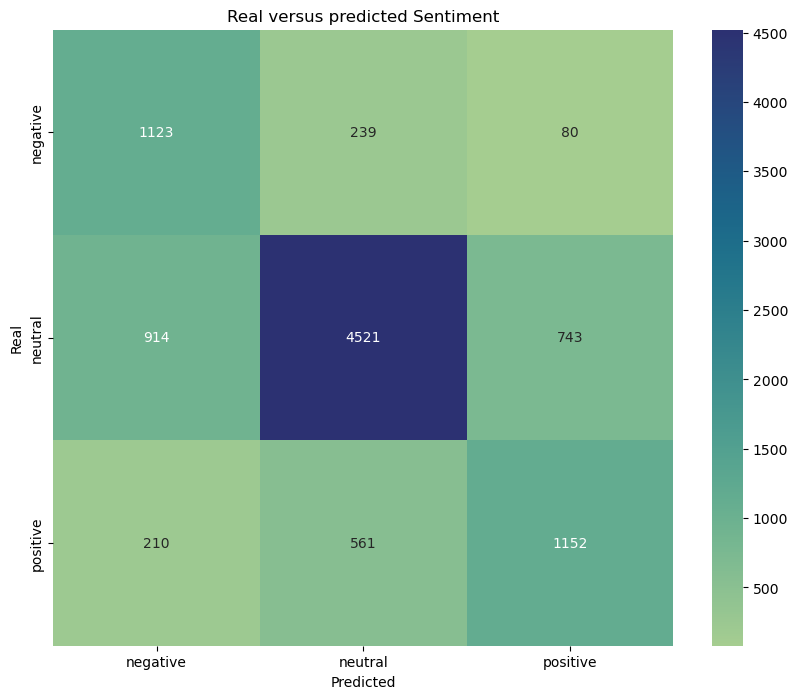

In [5]:
confusion_matrix = pd.crosstab(df["label"], df["predicted_label"]).reindex(index=classes, columns=classes)

plt.figure(figsize=(10,8))
sns.heatmap(confusion_matrix, annot=True, cmap="crest", fmt="d", xticklabels=classes, yticklabels=classes)
plt.title("Real versus predicted Sentiment")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

The confusion matrix shows the predicted sentiment mapped versus the actual sentiment. The biggest group are neutral tweets and these tweets seem to be predicted well but the values from the confusion matrix already hints at lower precision and recall score for both negative and positive tweets.

### Displaying Recall and Precision based on the CFM

In [6]:
#Recall
recall_pos = (1152) / (1152+561+210)
recall_neg = (1123) / (1123+239+80)
recall_neut = (4521) / (914+4521+743)

#Precision
precision_pos = (1152) / (80+743+1152)
precision_neg = (1123) / (1123+914+210) 
precision_neut = (4521) / (4521+239+561) 

<Figure size 1000x800 with 0 Axes>

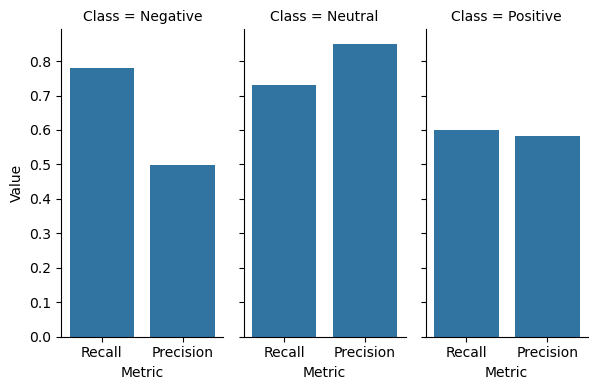

In [7]:
metrics_df = pd.DataFrame({
    "Class": ["Negative","Negative","Neutral","Neutral","Positive","Positive"],
    "Metric": ["Recall", "Precision"]*3,
    "Value": [recall_neg, precision_neg,recall_neut, precision_neut,recall_pos, precision_pos]
})
plt.figure(figsize=(10,8))
sns.catplot(
    metrics_df, kind="bar",
    x="Metric", y="Value", col="Class",
    height=4, aspect=.5,
)
plt.show();

These metrics already raise important questions for Phase 2.

So, since the recall of the positive samples (0.59906) is that low compared to Negative (0.77877) and Neutral Labels (0.73179), and also fairly conservative about actually labelling something positive (with precision being at around 0.583). The model may have it hard actually identifying positive sentiment.

Also it classifies Negative-sentiment only about 49% of the times right, which means that the model also can not really distinguish the sentiment just from the tweets by themselves. 49% is better than random - which would be 33%, however not as good as expected.


### Relplot

<Figure size 1000x800 with 0 Axes>

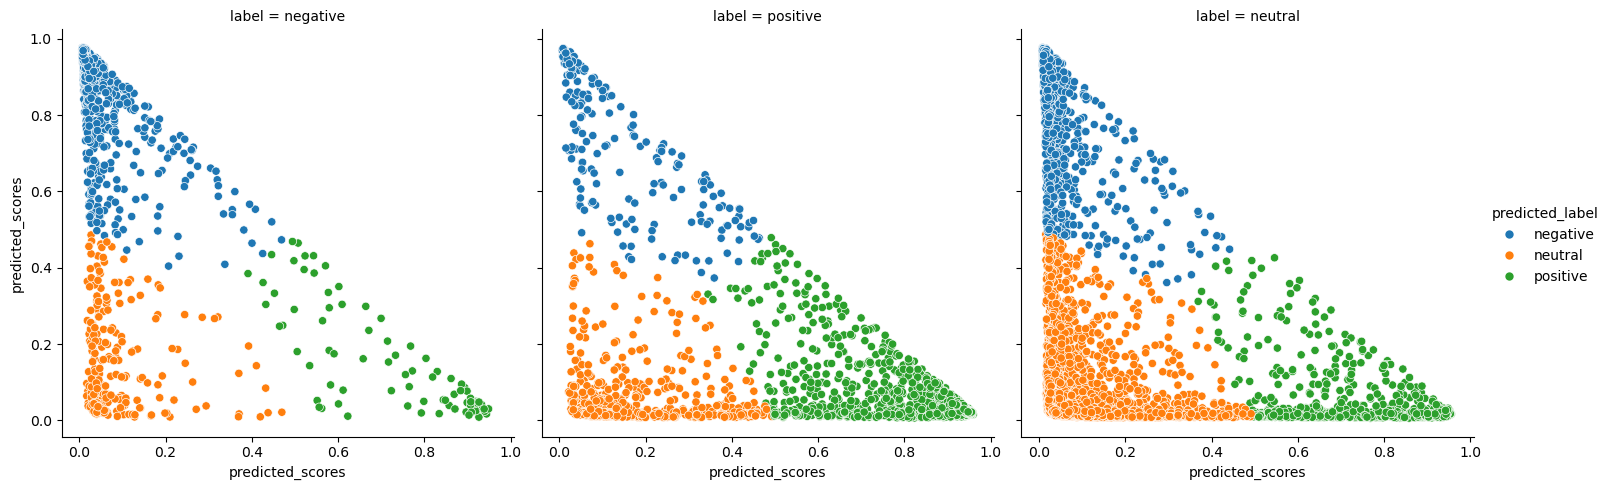

In [8]:
plt.figure(figsize=(10,8))
sns.relplot(
    data = df,
    x= df["predicted_scores"].apply(lambda d: d["positive"]),
    y=df["predicted_scores"].apply(lambda d: d["negative"]),
    col=df["label"],
    hue = df["predicted_label"],
)

plt.show()

The relplot (scatterplot) shows the distribution of predicted versus actual sentiment nicely. Again what is obvious from here is that the model struggles a lot for negative and positive tweets, while being good at predicting neutral tweets.

### Class distribution

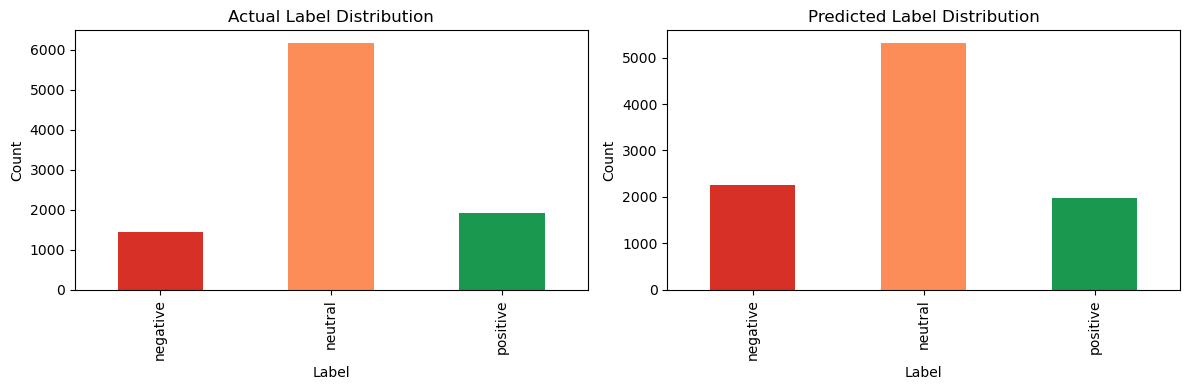

In [9]:
actual_counts = df["label"].value_counts().reindex(classes, fill_value=0)
pred_counts = df["predicted_label"].value_counts().reindex(classes, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

actual_counts.plot(kind="bar", ax=axes[0], color=["#d73027", "#fc8d59", "#1a9850"])
axes[0].set_title("Actual Label Distribution")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Count")

pred_counts.plot(kind="bar", ax=axes[1], color=["#d73027", "#fc8d59", "#1a9850"])
axes[1].set_title("Predicted Label Distribution")
axes[1].set_xlabel("Label")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

In both actual as well as predicted labels, the neutral (base) label dominates in terms of total amount. Additionally, this reflects reflects nicely the visualised rather low **precision** for both negative and positive tweets. Espeically in the negative case, the model predicts almost twice as many tweets as negative than there actually are.

### Confidence Histogramm

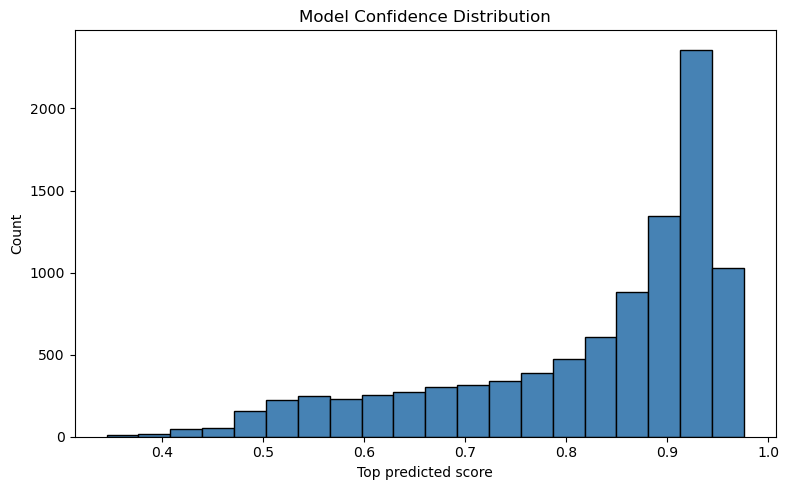

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(df["pred_top_score"], bins=20, edgecolor="black", color="steelblue")
plt.title("Model Confidence Distribution")
plt.xlabel("Top predicted score")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

The histogram shows that the model is overall quite confident in it's predictions. This is something that needs to be kept in mind when doing further analysis. 

### Boxplot

C:\Users\A8779\AppData\Local\Temp\ipykernel_15472\1117969367.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="predicted_label", y="pred_top_score", order=classes, palette="Set2")


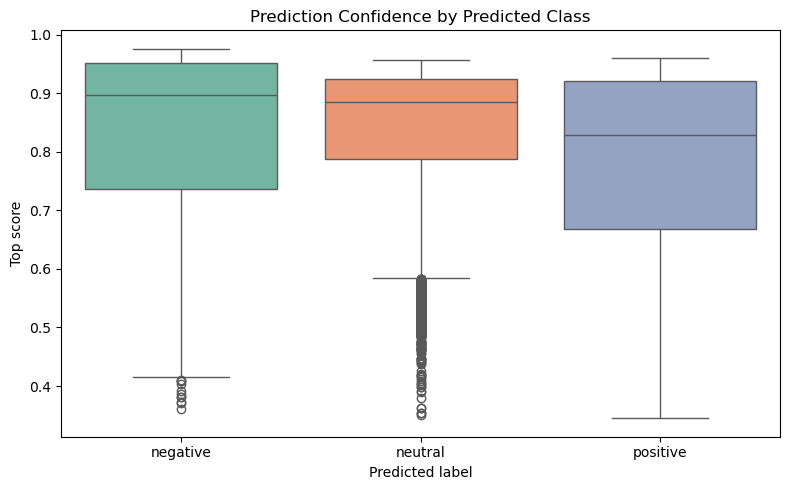

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="predicted_label", y="pred_top_score", order=classes, palette="Set2")
plt.title("Prediction Confidence by Predicted Class")
plt.xlabel("Predicted label")
plt.ylabel("Top score")
plt.tight_layout()
plt.show()

The boxplot shows per class what the histogram above showed in general. Overall, the model is confident in its predictions. Regardless, especially for the negative and neutral class, there are outliers to the bottom. 

### Prediction Uncertainty

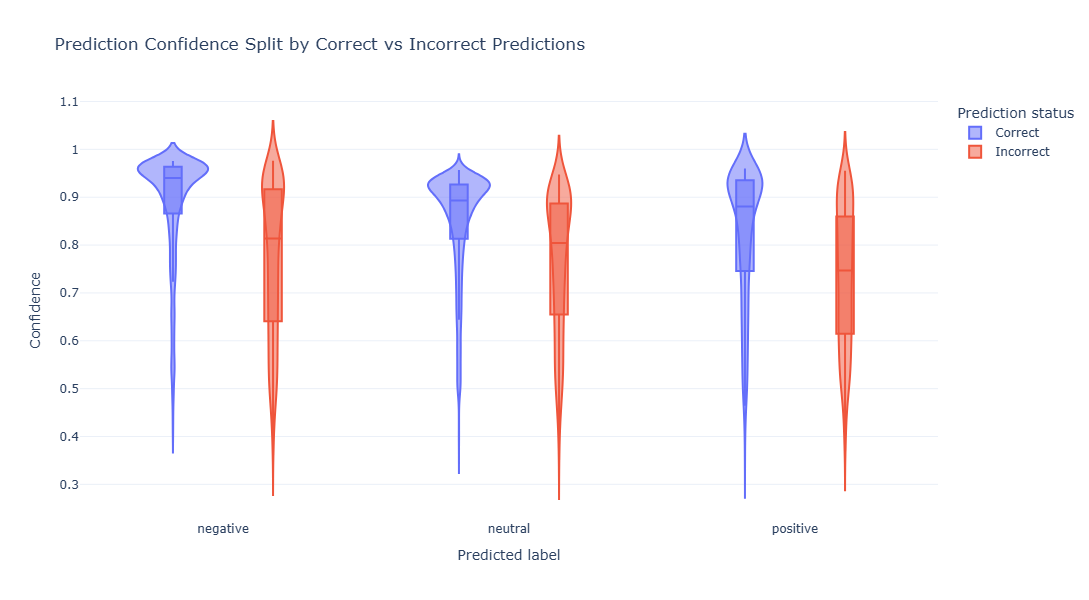

In [13]:
# split violin plot by whether the prediction was correct
plot_df = df[["text", "label", "predicted_label", "pred_top_score"]].copy()
plot_df["correct_prediction"] = plot_df["label"] == plot_df["predicted_label"]
plot_df["correct_prediction"] = plot_df["correct_prediction"].map({True: "Correct", False: "Incorrect"})

fig = px.violin(
    plot_df,
    x="predicted_label",
    y="pred_top_score",
    color="correct_prediction",
    box=True,
    points=False,
    category_orders={"predicted_label": classes, "correct_prediction": ["Correct", "Incorrect"]},
    title="Prediction Confidence Split by Correct vs Incorrect Predictions",
    labels={
        "pred_top_score": "Prediction confidence",
        "predicted_label": "Predicted label",
        "correct_prediction": "Prediction status",
    },
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Predicted label",
    yaxis_title="Confidence",
    legend_title_text="Prediction status",
    width=900,
    height=600,
)
fig.show()

This interactive violin plot shows that the model generally is less confident when making wrong predictions. This holds true for all three different classes and is especially apparent for the negative tweets. Less so for the positive but also for them the claim holds true.

## Tweet-length

We look into tweet length as a potential cause for errors. As a disclaimer, there is only a little amount of tweets above 26, hence we decided to ignore them.

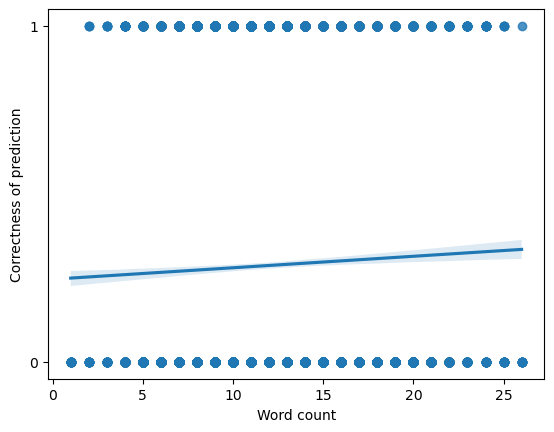

Corr coeff: 0.03506284428676409


In [50]:
wordcount = df["text"].str.split().str.len()
df_below27 = df[wordcount<27]
wordcounts_below27 = df_below27["text"].str.split().str.len()
error = (df_below27["label"] != df_below27["predicted_label"]).astype(int)
sns.regplot(x=wordcounts_below27, y=error)
plt.xlabel("Word count")
plt.yticks([0,1])
plt.ylabel("Correctness of prediction")
plt.show()

print("Corr coeff:", wordcounts_below25.corr(error))

The correlation is only 0.035. Hence there seems to be no clear linear relationsship between tweet length and correctness of prediction.

### Vectorized representation of tweets. 

For this task we look at the similiarity of tweets based on their cosine distance. We do this in order to see if there are any clear seperations possible based on the tweets themselves. 

In [16]:
model= SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [17]:
tweets_all = df.dropna(subset=["text"]).copy()
embeddings_all = model.encode(tweets_all["text"].tolist(), show_progress_bar=True)

Batches:   0%|          | 0/299 [00:00<?, ?it/s]

C:\Users\A8779\anaconda3\envs\mlpc2026\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


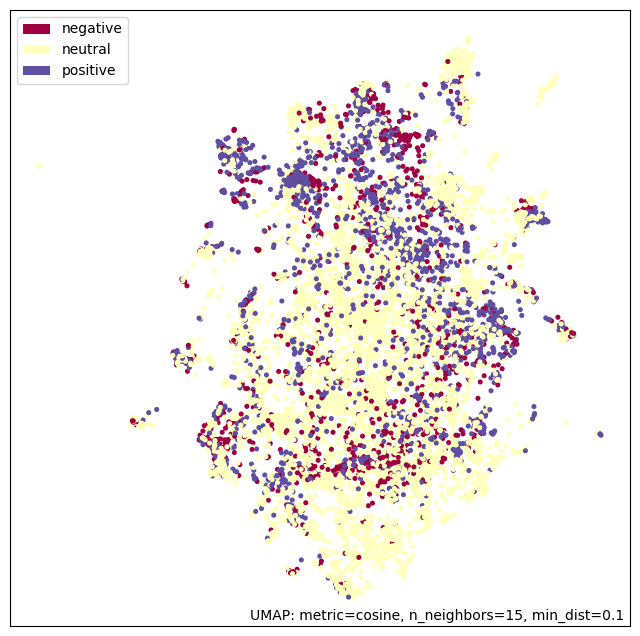

In [18]:
#Using UMAP to display the embeddings.  
reducer_all = umap.UMAP(n_components=2, random_state=16, metric='cosine').fit(embeddings_all)
plot = umap.plot.points(reducer_all, labels = tweets_all["label"])
plot.collections[0].set_sizes([7])

What becomes obvious here when looking at the plot is that there is no clear seperation based on tweets (full sentences). 

C:\Users\A8779\anaconda3\envs\mlpc2026\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


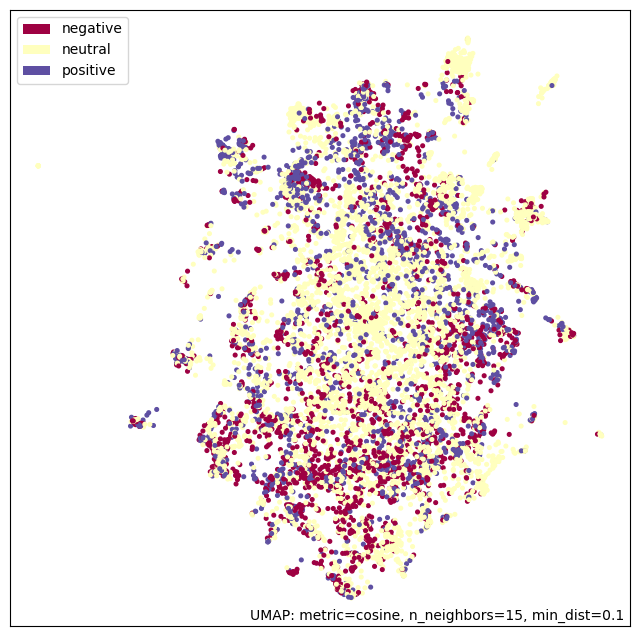

In [19]:
reducer_all = umap.UMAP(n_components=2, random_state=16, metric='cosine').fit(embeddings_all)
plot = umap.plot.points(reducer_all, labels = tweets_all["predicted_label"])
plot.collections[0].set_sizes([7])

It is even less seperated when looking at the predictions. This makes sense when thinking about the fact that in financial news a few words or even just one word can completely change the meaning of semantically similiar sentences. Think of two random example tweets:

1. The company's profit fell by 3% during this quarter.
2. The company's profit grew by 3% during this quarter.

Two almost identical sentences but an enitrely different meaning. 
The problem becomes even more apparent when looking at only bearish and bullish tweets.

In [20]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

finbert = pipeline("sentiment-analysis", model="ProsusAI/finbert")

textA = "The company's profit fell by 10% during this quarter."
resultA = finbert(textA)
print(resultA)
textB = "The company's profit grew by 10% during this quarter."
resultB = finbert(textB)
print(resultB)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[{'label': 'negative', 'score': 0.9757630825042725}]
[{'label': 'positive', 'score': 0.9540718197822571}]


Both are predicted as expected. However, their cosine similarity is really high.

In [21]:
from sklearn.metrics.pairwise import cosine_similarity

example_embedding1, example_embedding2 = model.encode([textA, textB])
score = cosine_similarity([example_embedding1],[example_embedding2])[0][0]
print(score)

0.83851665


In [22]:
df_no_neutral = df[df["label"] != "neutral"].copy()

In [23]:
tweets_no_neutral = df_no_neutral.dropna(subset=["text"]).copy()
embeddings_no_neutral = model.encode(tweets_no_neutral["text"].tolist(), show_progress_bar=True)

Batches:   0%|          | 0/106 [00:00<?, ?it/s]

C:\Users\A8779\anaconda3\envs\mlpc2026\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


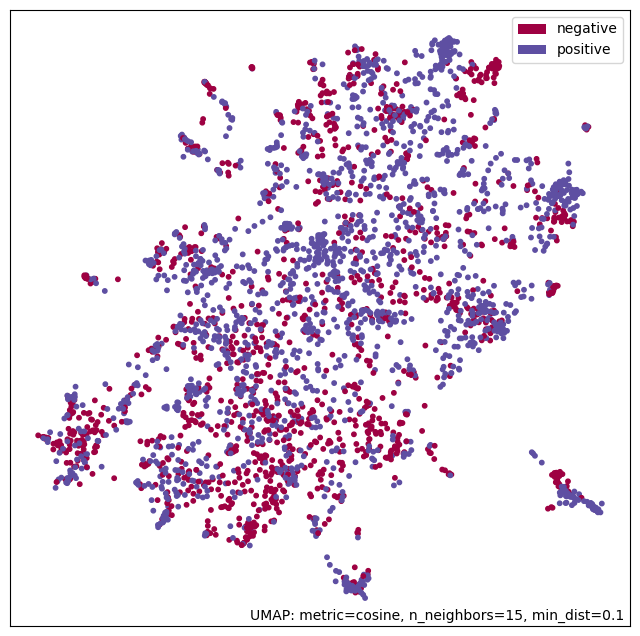

In [24]:
reducer_no_neutral = umap.UMAP(n_components=2, random_state=16, metric='cosine').fit(embeddings_no_neutral)
plot = umap.plot.points(reducer_no_neutral, labels = tweets_no_neutral["label"])
plot.collections[0].set_sizes([10])

In the first UMAP-plot, one could argue that neutral tweets could be somewhat seperated but here semantically, there is no clear distinction at all between bullish and bearish tweets. However, as explained in the beginning, these 2 categories are exactly what we need to pay extra attentation to if we were to build a sementiment based trading strategy!

This leads to the conclusion that the Finbert's prediction is mainly driven by words instead of sentences and the context of the sentence seems to be irrelevant. This explains the model's precision for negative and positive tweets. It ignores the context and simply picks up 1 or two important words and then predicts. This leads to a lot of false predictions. We will analyse this more in depth now. 

### First Case - Label: Bear but Predition: Bull

Now, we investigate the first of our two cases: Bearish tweets that were mispredicted as bullish. For that, we defined a list of bullish words (that we are associated with positive stock trends) and measured their occurence among wrongly predicted tweets. **As a disclaimer**, this was not done by looking at individual tweets but done beforehand without "finetuning" on tweets! 

In [25]:
bullish_words = {
    "gains", "gain", "overweight", "outperform", 
    "soars", "boom", "booming", "higher",
    "gained", "buys", "buy", "beats"
}

In [26]:
df_bear_but_pred_bull = df_no_neutral[
    (df_no_neutral["label"] == "negative")
    & (df_no_neutral["predicted_label"] == "positive")
    ]

df_bear_but_pred_neutral= df_no_neutral[
    (df_no_neutral["label"] == "negative")
    & (df_no_neutral["predicted_label"] == "neutral")
    ]

df_bear_and_pred_bear= df_no_neutral[
    (df_no_neutral["label"] == "negative")
    & (df_no_neutral["predicted_label"] == "negative")
    ]

matches_bull = df_bear_but_pred_bull["text"].str.contains(r"\b(?:" + "|".join(bullish_words)+r")\b", case=False, na=False).mean()
matches_base = df_bear_but_pred_neutral["text"].str.contains(r"\b(?:" + "|".join(bullish_words)+r")\b", case=False, na=False).mean() 
matches_bear = df_bear_and_pred_bear["text"].str.contains(r"\b(?:" + "|".join(bullish_words)+r")\b", case=False, na=False).mean() 

Bear - Bear 3.383793410507569
Bear - Base 6.694560669456067
Bear - Bull 18.75


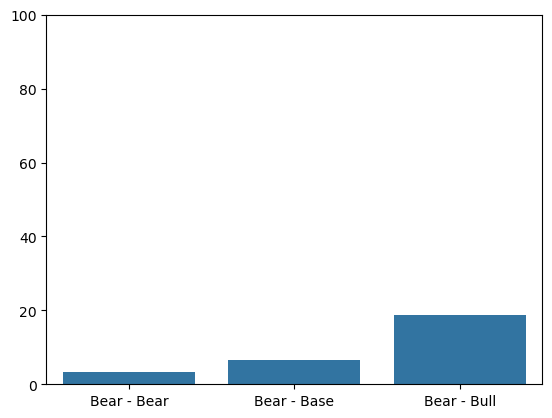

In [27]:
print("Bear - Bear", matches_bear*100)
print("Bear - Base", matches_base*100)
print("Bear - Bull", matches_bull*100)
sns.barplot(
    x = ["Bear - Bear", "Bear - Base", "Bear - Bull",],
    y = [matches_bear*100, matches_base*100, matches_bull*100]
)
plt.ylim(0,100)
plt.show()

The plot shows a clear increase in misspredictions when these words occur. Also interesting here is that there are quite some "bear to base" cases which also include some of these words. This further supports our hypothesis because it means that these words pushed the sentiment of these tweets into a more positive direction.

This apparently word-driven behaviour brings an additional problem:

In [28]:
textC = "The company's profit grew by 0% during this quarter."
resultC = finbert(textC)
print(resultC)
textD = "The company's profit grew by 100% during this quarter."
resultD = finbert(textD)
print(resultD)

[{'label': 'positive', 'score': 0.9536755084991455}]
[{'label': 'positive', 'score': 0.9513593316078186}]


TextD achieves a lower score than textB despite being a much positiver message. In fact, textC here is not really a positive message at all. 

And it can become even worse. According to Finbert these 2 sentences carry similiar optimistic sentiment:

In [29]:
textE = "The company's cost grew by 100% during this quarter."
resultE = finbert(textE)
print(resultE)
textF = "The company's profit grew by 100% during this quarter."
resultF = finbert(textF)
print(resultF)

[{'label': 'positive', 'score': 0.9457692503929138}]
[{'label': 'positive', 'score': 0.9513593316078186}]


In [30]:
df_bear = df[(df["label"] == "negative") & (df["predicted_label"] != "neutral")].copy()

In [31]:
tweets_bear = df_bear.dropna(subset=["text"]).copy()
embeddings_bear = model.encode(tweets_bear["text"].tolist(), show_progress_bar=True)

Batches:   0%|          | 0/38 [00:00<?, ?it/s]

C:\Users\A8779\anaconda3\envs\mlpc2026\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


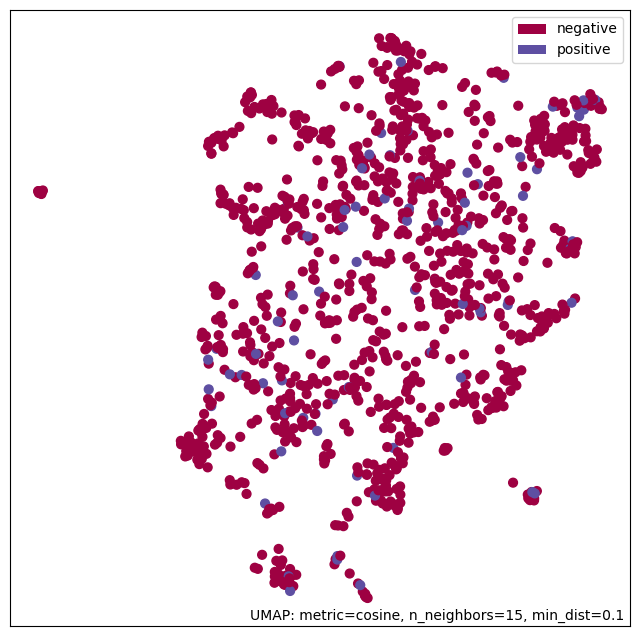

In [32]:
reducer_bear = umap.UMAP(n_components=2, random_state=16, metric='cosine').fit(embeddings_bear)
plot = umap.plot.points(reducer_bear, labels = tweets_bear["predicted_label"])
plot.collections[0].set_sizes([40])

Again we see the same recurring pattern: There seems no semantically distinct groups that could cause misclassification as well as correct classification. This also explains the low correlation between tweet length and correctness of prediction. If one "trigger-word" can simply change the predicted sentiment of the entire sentence regardless of the sentence itself, then the length itself most likely is not that important as well.

### Second Case - Label: Bull but Predition: Bear

Our second case is exactly the opposite case that we mentioned earlier: Bullish tweets that are mispredicted as bearish. For that, we defined a list of bearish words (that we are associated with positive stock trends) and measured their occurence among wrongly predicted tweets. As a disclaimer, this was not done by looking at individual tweets but done beforehand without "finetuning" on tweets!

In [33]:
bearish_words = {
    "crashes", "loss", "underweight", "underperform", 
    "losses", "bust", "bursting", "lower",
    "lost", "sell", "sold", "misses",
    "crash", "decline", "drop"
}

In [34]:
df_bull_but_pred_bear = df_no_neutral[
    (df_no_neutral["label"] == "positive")
    & (df_no_neutral["predicted_label"] == "negative")
    ]

df_bull_but_pred_neutral= df_no_neutral[
    (df_no_neutral["label"] == "positive")
    & (df_no_neutral["predicted_label"] == "neutral")
    ]

df_bull_and_pred_bull = df_no_neutral[
    (df_no_neutral["label"] == "positive")
    & (df_no_neutral["predicted_label"] == "positive")
    ]

matches_bull_ = df_bull_but_pred_bear["text"].str.contains(r"\b(?:" + "|".join(bearish_words)+r")\b", case=False, na=False).mean()
matches_base_= df_bull_but_pred_neutral["text"].str.contains(r"\b(?:" + "|".join(bearish_words)+r")\b", case=False, na=False).mean() 
matches_bear_ = df_bull_and_pred_bull["text"].str.contains(r"\b(?:" + "|".join(bearish_words)+r")\b", case=False, na=False).mean() 

Bull - Bear 0.78125
Bull - Base 1.06951871657754
Bull - Bull 6.190476190476191


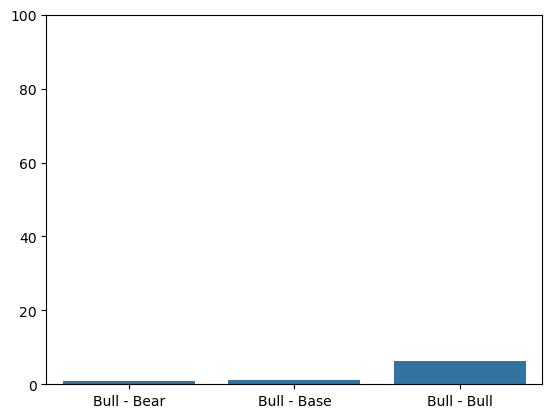

In [35]:
print("Bull - Bear", matches_bear_*100)
print("Bull - Base", matches_base_*100)
print("Bull - Bull", matches_bull_*100)
sns.barplot(
    x = ["Bull - Bear", "Bull - Base", "Bull - Bull",],
    y = [matches_bear_*100, matches_base_*100, matches_bull_*100]
)
plt.ylim(0,100)
plt.show()

Here our selected words does not make any noticeable impact. Rather the opposite, they appear in a lot of correctly identified tweets. We decided to leave it in for completeness.

In [36]:
df_bull = df[(df["label"] == "positive") & (df["predicted_label"] != "neutral")].copy()

In [37]:
tweets_bull = df_bull.dropna(subset=["text"]).copy()
embeddings_bull = model.encode(tweets_bull["text"].tolist(), show_progress_bar=True)

Batches:   0%|          | 0/43 [00:00<?, ?it/s]

C:\Users\A8779\anaconda3\envs\mlpc2026\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


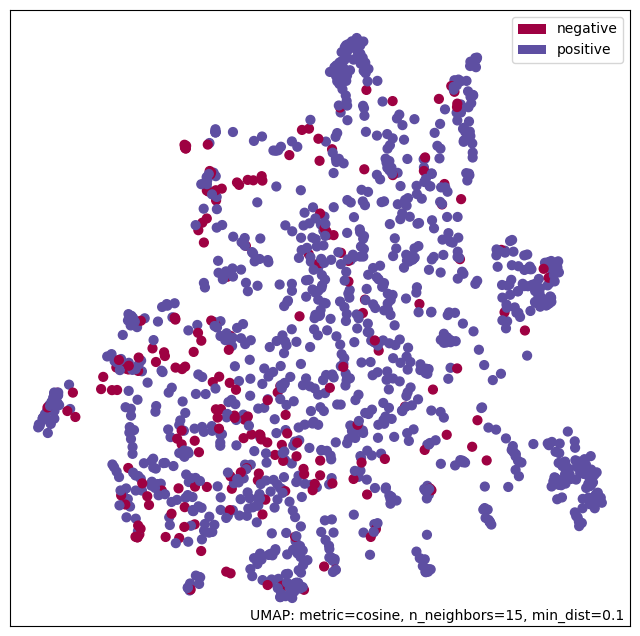

In [38]:
reducer_bull = umap.UMAP(n_components=2, random_state=16, metric='cosine').fit(embeddings_bull)
plot = umap.plot.points(reducer_bull, labels = tweets_bull["predicted_label"])
plot.collections[0].set_sizes([40])

In general, we could not identify any clear behaviour from these misinterpreted tweets. Also when looking manually through the misclassified tweets, to us there appeared no patterns. Tweets that were clearly bullish (no double negation, no bearish words).  